# Intelligent Warehouse Slotting Optimization
**Business Problem:** Warehouse slotting plays an important role in operational efficiency by determining where inventory is stored. Parts with higher demand may not always be positioned in locations that best support their usage patterns, which can contribute to unnecessary material movement and inefficient use of warehouse space.
**Project Objective:** The objective of this project is to analyze historical warehouse inventory, usage, and storage-location data to identify patterns that can support improved slotting decisions. Exploratory data analysis and feature engineering are used to examine relationships between SKU demand, inventory levels, and current storage positions. The analysis focuses particularly on identifying whether high-usage parts are positioned in less accessible storage locations. A baseline regression model is then developed to evaluate whether available inventory and storage-location characteristics can help predict SKU usage and provide a foundation for future slotting optimization.

### Data Privacy Note
This project uses proprietary warehouse operational data. The raw dataset is not included in the public repository, and row-level outputs containing part numbers, descriptions, exact storage locations, or inventory records have been removed from this submission notebook. Aggregate analytical results, visualizations, and model results are retained.


## Research questions and hypotheses

**RQ1 — Demand and inventory:** How strongly is Average Daily Usage (ADU) associated with current inventory? **H1:** Higher-usage SKUs tend to have higher inventory, although the relationship is not perfect.

**RQ2 — Vertical placement:** Are high-usage SKUs concentrated at lower, more accessible levels (A–B) rather than upper levels (E–H)? **H2:** Some aisles will show high-usage SKUs at upper levels, identifying *review candidates*, not proven mis-slotting.

**RQ3 — Predictive baseline:** Can inventory and existing location attributes predict log-transformed ADU? **H3:** A simple linear baseline will capture some variation but will leave meaningful unexplained demand variation.

**Scope:** SM101 is small-parts storage; GW areas store bulk parts. Vertical level A is lowest and H highest. Observational analysis cannot establish travel-time savings or physical relocation feasibility.

## **Data Understanding**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Excel workbook
file_path = '/content/Warehouse Slotting Captsone- Data.xlsx'

# View the available worksheets
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

['USAGE', 'Warehouse+Reserved+Places (17)', 'Sheet1']

In [2]:
df = pd.read_excel(file_path, sheet_name='USAGE')


df.head()

,Part number,Part description,Average Daily Usage,Warehouse Storage Location,Current Inventory levels (in pieces),Distance/Effort,As of Aug 24th
0,100012,NUT M4 8 ZND HEX,73.8,NaN,NaN,NaN,NaN
1,100037,NUT LOCK M10 CL8 ZND HEX 1.5P,156.6,NaN,600.0,NaN,NaN
2,10090811,NUT TIE ROD M10X1.25X90,61.2,SM101.20.H.36,700.0,NaN,NaN
3,101792A1,"END, DIAGNOSTIC NIPPLE",5.0,SM101.20.F.32,NaN,NaN,NaN
4,102929A1,DECAL WARNING,6.2,NaN,NaN,NaN,NaN


In [3]:
df.columns.tolist()

['Part number',
 'Part description',
 'Average Daily Usage',
 'Warehouse Storage Location',
 'Current Inventory levels (in pieces)',
 'Distance/Effort',
 'As of Aug 24th ']

In [4]:
df.columns.tolist()

['Part number',
 'Part description',
 'Average Daily Usage',
 'Warehouse Storage Location',
 'Current Inventory levels (in pieces)',
 'Distance/Effort',
 'As of Aug 24th ']

In [5]:
df.shape

(4994, 7)

In [6]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 7 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Part number                           4994 non-null   object 
 1   Part description                      4992 non-null   object 
 2   Average Daily Usage                   4994 non-null   float64
 3   Warehouse Storage Location            2486 non-null   object 
 4   Current Inventory levels (in pieces)  3505 non-null   float64
 5   Distance/Effort                       0 non-null      float64
 6   As of Aug 24th                        1 non-null      object 
dtypes: float64(3), object(4)
memory usage: 273.2+ KB


In [7]:

df.describe()

,Average Daily Usage,Current Inventory levels (in pieces),Distance/Effort
count,4994.000000,3505.000000,0.0
mean,126.003044,476.192810,NaN
std,3723.431437,872.639624,NaN
min,5.000000,1.000000,NaN
25%,5.000000,58.000000,NaN
50%,5.000000,184.000000,NaN
75%,20.750000,560.000000,NaN
max,251889.600000,17400.000000,NaN


In [8]:

df.isnull().sum()

,0
Part number,0
Part description,2
Average Daily Usage,0
Warehouse Storage Location,2508
Current Inventory levels (in pieces),1489
Distance/Effort,4994
As of Aug 24th,4993


In [9]:

df.duplicated().sum()

np.int64(0)

In [10]:

df['Part number'].duplicated().sum()

np.int64(0)

In [11]:
pd.crosstab(
    df['Warehouse Storage Location'].isnull(),
    df['Current Inventory levels (in pieces)'].isnull(),
    rownames=['Storage Location Missing'],
    colnames=['Inventory Missing']
)

Inventory Missing,False,True
Storage Location Missing,,
False,2063,423
True,1442,1066


In [12]:
# Display the 10 parts with the highest Average Daily Usage
df.nlargest(10, 'Average Daily Usage')[
    ['Part number', 'Part description', 'Average Daily Usage',
     'Warehouse Storage Location', 'Current Inventory levels (in pieces)']
]

,Part number,Part description,Average Daily Usage,Warehouse Storage Location,Current Inventory levels (in pieces)
2368,84338534,SEAL,251889.6,SM100.33.A.24,3136.0
961,47874049,STRIP SEALING,44410.4,NaN,1186.0
2419,84353803,TRIM,35486.2,SM100.33.C.08,1370.0
2442,84361032,HOSE WASHER WINDSHIELD,33863.2,SM100.33.C.06,11924.0
3908,91734935,STRIP SEALING,31541.2,NaN,NaN
3144,87301340,"SEALANT, POLY SIKA 227 HITACHI",11580.6,NaN,NaN
406,47394323,HOSE FUEL LINE BULK ITEM,9848.0,SM100.33.C.24,550.0
2718,84554254,"TRIM, EDGE, 6.35MM PANEL, BULK",7894.6,SM100.33.C.08,1832.0
4231,92133137,TAPE RED VINYL ELECTRICAL,5726.0,NaN,NaN
1085,47950719,GREASE LUBRIPLATE 105 1 G BULK,3759.6,NaN,NaN


# **Feature Engineering 1**

In [13]:
# Feature Engineering
# Create a log-transformed version of Average Daily Usage
df['Log_Average_Daily_Usage'] = np.log1p(df['Average Daily Usage'])

df[['Average Daily Usage', 'Log_Average_Daily_Usage']].head()

,Average Daily Usage,Log_Average_Daily_Usage
0,73.8,4.314818
1,156.6,5.060060
2,61.2,4.130355
3,5.0,1.791759
4,6.2,1.974081


In [14]:
# View parts with missing descriptions
df[df['Part description'].isnull()]

,Part number,Part description,Average Daily Usage,Warehouse Storage Location,Current Inventory levels (in pieces),Distance/Effort,As of Aug 24th,Log_Average_Daily_Usage
33,127083A1,NaN,92.0,NaN,NaN,NaN,NaN,4.532599
1971,60-6423T1,NaN,5.0,NaN,NaN,NaN,NaN,1.791759


In [15]:

df['Part description'] = df['Part description'].fillna('Unknown')


df['Part description'].isnull().sum()

np.int64(0)

In [16]:
# Compare Average Daily Usage based on whether inventory is missing
df.groupby(
    df['Current Inventory levels (in pieces)'].isnull()
)['Average Daily Usage'].describe()

,count,mean,std,min,25%,50%,75%,max
Current Inventory levels (in pieces),,,,,,,,
False,3505.0,137.092268,4404.370983,5.0,5.0,5.0,20.6,251889.6
True,1489.0,99.899799,916.151406,5.0,5.0,5.0,21.6,31541.2


In [17]:
# View a sample of parts with missing inventory
df[df['Current Inventory levels (in pieces)'].isnull()][
    ['Part number',
     'Part description',
     'Average Daily Usage',
     'Warehouse Storage Location']
].head(20)

,Part number,Part description,Average Daily Usage,Warehouse Storage Location
0,100012,NUT M4 8 ZND HEX,73.8,NaN
3,101792A1,"END, DIAGNOSTIC NIPPLE",5.0,SM101.20.F.32
4,102929A1,DECAL WARNING,6.2,NaN
6,10791411,"NUT, THIN, M16X1.50 04 ZND",5.0,NaN
9,120038,BOLT CRG M8X30 8.8 ZND 1.25P,33.8,NaN
10,120039,BOLT CRG M8X50 8.8 ZND 1.25P,29.2,NaN
11,120041,BOLT CRG M10X20 8.8 ZND 1.5P,10.2,NaN
12,120044,BOLT CRG M12X30 8.8 ZND 1.75P,5.0,SM101.20.B.07
13,120052,SOCK.HD. SCREW,5.0,NaN
14,120056,BOLT M6X50 8.8 ZND HEX 1.0P,105.0,NaN


In [18]:
# Create indicator for inventory data availability
df['Inventory_Available'] = df['Current Inventory levels (in pieces)'].notnull().astype(int)

df[['Current Inventory levels (in pieces)', 'Inventory_Available']].head(10)

,Current Inventory levels (in pieces),Inventory_Available
0,NaN,0
1,600.0,1
2,700.0,1
3,NaN,0
4,NaN,0
5,457.0,1
6,NaN,0
7,222.0,1
8,295.0,1
9,NaN,0


In [19]:
# Number of unique warehouse storage locations
df['Warehouse Storage Location'].nunique()

1552

In [20]:
# Most common warehouse storage locations
df['Warehouse Storage Location'].value_counts().head(20)

,count
Warehouse Storage Location,
SM101.19.F.18,7
SM101.20.B.27,7
SM101.19.G.03,7
SM101.19.G.01,7
SM101.20.B.35,6
SM101.20.H.45,6
SM101.21.B.42,6
SM101.18.A.04,6
SM101.20.F.43,6


In [21]:
# Sample of unique warehouse locations
df['Warehouse Storage Location'].dropna().unique()[:30]

array(['SM101.20.H.36', 'SM101.20.F.32', 'SM101.18.C.31', 'SM101.18.F.20',
       'SM101.18.H.46', 'SM101.20.B.07', 'SM101.18.D.41', 'SM101.20.F.08',
       'SM101.19.E.23', 'SM101.18.D.34', 'SM101.19.A.32', 'SM101.19.B.30',
       'SM101.21.D.16', 'SM101.20.H.39', 'SM101.20.D.40', 'SM101.18.H.13',
       'SM101.18.C.11', 'SM101.18.D.21', 'SM101.19.E.37', 'SM101.19.F.01',
       'SM101.19.D.21', 'SM101.19.C.20', 'SM101.21.B.40', 'SM101.19.F.07',
       'SM101.20.G.34', 'SM101.21.B.32', 'SM101.20.A.44', 'SM101.18.B.11',
       'SM101.19.F.09', 'SM101.19.G.04'], dtype=object)

# **Feature Engineering 2**

In [22]:
#Feature Engineering
# Split warehouse storage location into individual components
location_parts = df['Warehouse Storage Location'].str.split('.', expand=True)

df['Warehouse_Area'] = location_parts[0]
df['Aisle'] = location_parts[1]
df['Vertical_Level'] = location_parts[2]
df['Horizontal_Position'] = location_parts[3]

# Preview the new features
df[
    ['Warehouse Storage Location',
     'Warehouse_Area',
     'Aisle',
     'Vertical_Level',
     'Horizontal_Position']
].head(10)

,Warehouse Storage Location,Warehouse_Area,Aisle,Vertical_Level,Horizontal_Position
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,SM101.20.H.36,SM101,20,H,36
3,SM101.20.F.32,SM101,20,F,32
4,NaN,NaN,NaN,NaN,NaN
5,SM101.18.C.31,SM101,18,C,31
6,NaN,NaN,NaN,NaN,NaN
7,SM101.18.F.20,SM101,18,F,20
8,SM101.18.H.46,SM101,18,H,46
9,NaN,NaN,NaN,NaN,NaN


In [23]:

df['Storage_Location_Available'] = (
    df['Warehouse Storage Location'].notnull().astype(int)
)

df[['Warehouse Storage Location', 'Storage_Location_Available']].head(10)

,Warehouse Storage Location,Storage_Location_Available
0,NaN,0
1,NaN,0
2,SM101.20.H.36,1
3,SM101.20.F.32,1
4,NaN,0
5,SM101.18.C.31,1
6,NaN,0
7,SM101.18.F.20,1
8,SM101.18.H.46,1
9,NaN,0


In [24]:
# Review missing values after initial cleaning and feature creation
df.isnull().sum()

,0
Part number,0
Part description,0
Average Daily Usage,0
Warehouse Storage Location,2508
Current Inventory levels (in pieces),1489
Distance/Effort,4994
As of Aug 24th,4993
Log_Average_Daily_Usage,0
Inventory_Available,0
Warehouse_Area,2508


In [25]:
# Find locations that exist but did not produce a Horizontal Position
df[
    df['Warehouse Storage Location'].notnull() &
    df['Horizontal_Position'].isnull()
][['Warehouse Storage Location']].value_counts()

,count
Warehouse Storage Location,
GW320.CAB.01,2
SMROPS16.C.00,2
SMM1825.C.02,1
SMM1825.C.03,1
SMM1825.C.05,1
...,...
SMROPS16.C.44,1
SMROPS16.C.45,1
SMROPS16.C.46,1


In [26]:

df['Location_Component_Count'] = (
    df['Warehouse Storage Location'].str.count(r'\.') + 1
)

# Identify standard four-component locations
df['Standard_Location_Format'] = (
    df['Location_Component_Count'] == 4
).astype(int)

df[
    ['Warehouse Storage Location',
     'Location_Component_Count',
     'Standard_Location_Format']
].head(10)

,Warehouse Storage Location,Location_Component_Count,Standard_Location_Format
0,NaN,NaN,0
1,NaN,NaN,0
2,SM101.20.H.36,4.0,1
3,SM101.20.F.32,4.0,1
4,NaN,NaN,0
5,SM101.18.C.31,4.0,1
6,NaN,NaN,0
7,SM101.18.F.20,4.0,1
8,SM101.18.H.46,4.0,1
9,NaN,NaN,0


In [27]:
df['Standard_Location_Format'].value_counts()

,count
Standard_Location_Format,
0,2600
1,2394


## Data-quality audit and cleaning rationale

The source contains **4,994 part records** (as documented in the README). Missing storage locations are **not** inferred, since assigning an aisle or level without evidence would bias the slotting analysis. Missing inventory is retained for EDA and median-imputed **inside the training pipeline** for modeling. Missing descriptions are labeled `Unknown` for presentation only. Part-number duplicates should be examined as potential multiple records rather than deleted automatically. Extreme ADU values are retained because units of measure may differ; log1p reduces their visual influence without asserting that they are errors.

The following reproducible audit reports missingness, duplicate counts, and distribution tails; interpret the results before deciding whether additional cleaning is appropriate.

In [28]:
# Data-quality audit: aggregate counts only (no proprietary row-level records)
audit_cols = ['Part number', 'Average Daily Usage',
              'Current Inventory levels (in pieces)', 'Warehouse Storage Location']
audit = pd.DataFrame({
    'missing_count': df[audit_cols].isna().sum(),
    'missing_pct': (100 * df[audit_cols].isna().mean()).round(1)
})
display(audit)
print('Duplicate full rows:', int(df.duplicated().sum()))
print('Duplicate part numbers:', int(df['Part number'].duplicated().sum()))
print('ADU percentiles:', df['Average Daily Usage'].quantile([.50, .90, .95, .99]).round(2).to_dict())
print('Negative ADU records:', int((df['Average Daily Usage'] < 0).sum()))
print('Negative inventory records:', int((df['Current Inventory levels (in pieces)'] < 0).sum()))

,missing_count,missing_pct
Part number,0,0.0
Average Daily Usage,0,0.0
Current Inventory levels (in pieces),1489,29.8
Warehouse Storage Location,2508,50.2


Duplicate full rows: 0
Duplicate part numbers: 0
ADU percentiles: {0.5: 5.0, 0.9: 55.34, 0.95: 126.87, 0.99: 773.38}
Negative ADU records: 0
Negative inventory records: 0


# 4. **Exploratory Data Analysis (EDA)**

This section explores the distributions and relationships among part usage, inventory levels, and warehouse storage characteristics to identify patterns relevant to warehouse slotting optimization.

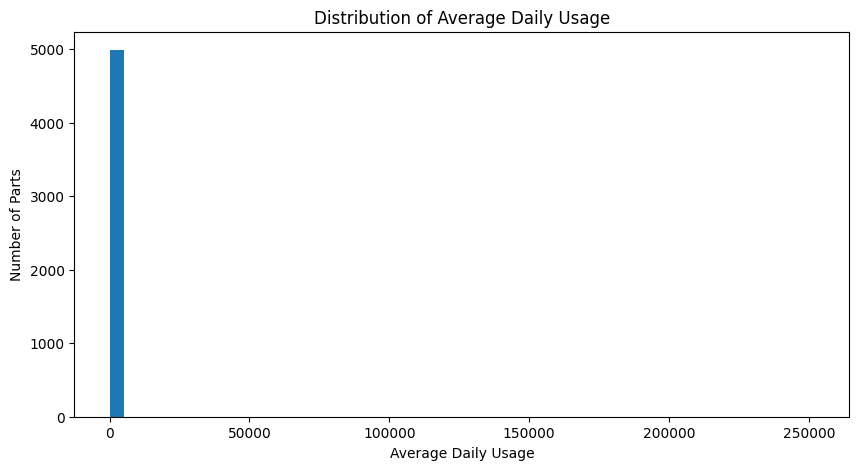

In [29]:
plt.figure(figsize=(10, 5))

plt.hist(df['Average Daily Usage'], bins=50)

plt.title('Distribution of Average Daily Usage')
plt.xlabel('Average Daily Usage')
plt.ylabel('Number of Parts')

plt.show()


**Observation**: Average Daily Usage is highly right-skewed, with a small number of parts having substantially higher usage values than the majority of the dataset. Some of these extreme values may reflect differences in units of measure for certain materials. Because unit-of-measure conversion information was unavailable, these observations were retained rather than removed. A log transformation was used to reduce the influence of extreme values and provide a clearer view of the usage distribution.

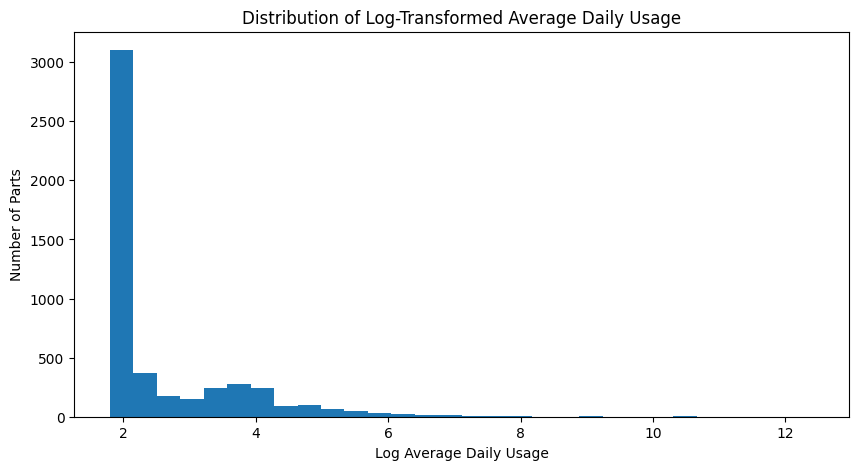

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(df['Log_Average_Daily_Usage'], bins=30)

plt.title('Distribution of Log-Transformed Average Daily Usage')
plt.xlabel('Log Average Daily Usage')
plt.ylabel('Number of Parts')

plt.show()

**Observation**: After applying the log transformation, the distribution of Average Daily Usage becomes easier to interpret. A large concentration of parts has relatively low daily usage, while progressively fewer parts have higher usage. The large concentration near a log value of 1.79 corresponds primarily to parts with an Average Daily Usage of 5. Although the distribution remains right-skewed, the transformation reduces the impact of extremely large values and makes differences among the majority of parts more visible.

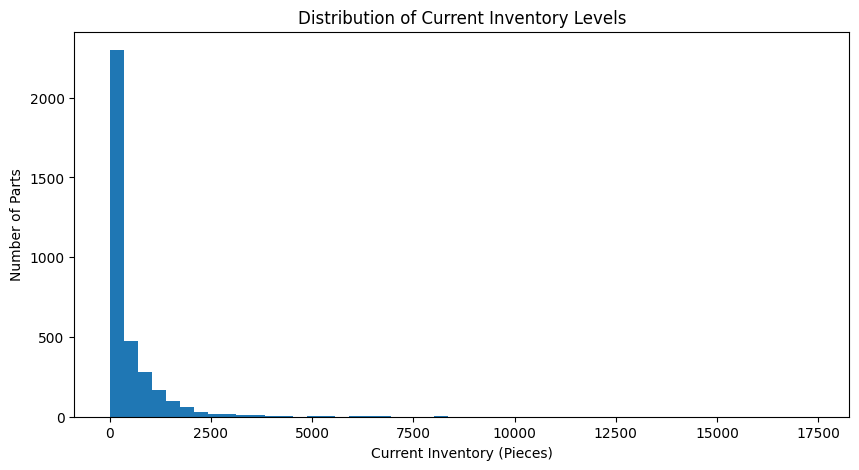

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['Current Inventory levels (in pieces)'].dropna(),
    bins=50
)

plt.title('Distribution of Current Inventory Levels')
plt.xlabel('Current Inventory (Pieces)')
plt.ylabel('Number of Parts')

plt.show()

**Observation**: Current Inventory Levels are highly right-skewed. Most parts have relatively low inventory quantities, while a small number of parts have substantially larger inventory levels. Because extreme inventory values can dominate visualizations and modeling, a log transformation will be considered to better represent the overall distribution.

In [32]:

df['Log_Current_Inventory'] = np.log1p(
    df['Current Inventory levels (in pieces)']
)

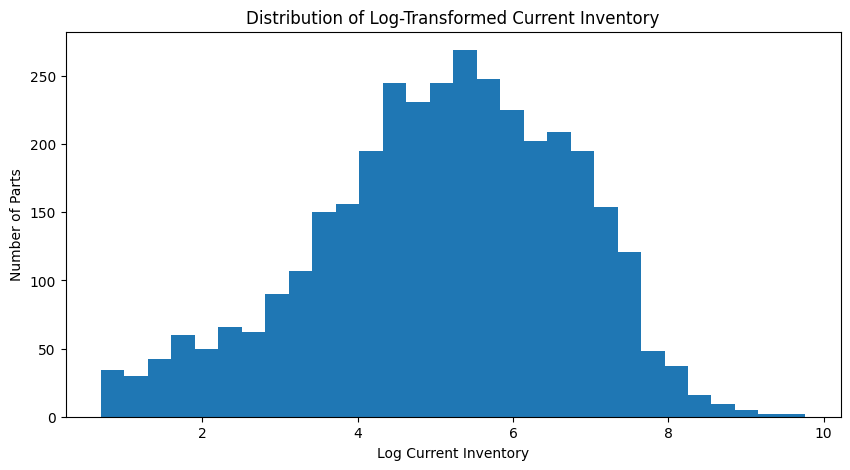

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['Log_Current_Inventory'].dropna(),
    bins=30
)

plt.title('Distribution of Log-Transformed Current Inventory')
plt.xlabel('Log Current Inventory')
plt.ylabel('Number of Parts')

plt.show()

**Observation**: The log transformation substantially reduced the right skew in Current Inventory Levels and produced a more balanced distribution. The transformed variable will be useful for subsequent analysis and modeling because extreme inventory values will have less influence while the relative differences between parts are preserved.

Relationship between Usage and Inventory- Do higher-usage parts generally have higher inventory levels?

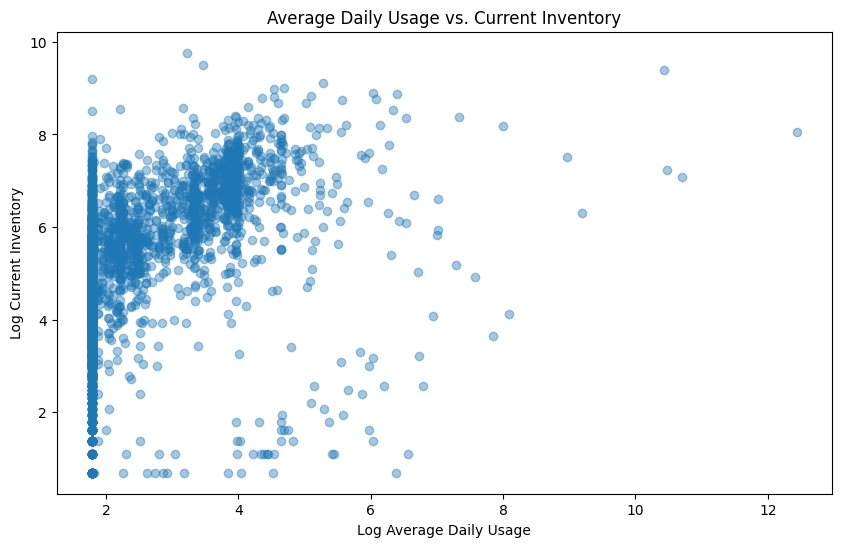

In [34]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Log_Average_Daily_Usage'],
    df['Log_Current_Inventory'],
    alpha=0.4
)

plt.title('Average Daily Usage vs. Current Inventory')
plt.xlabel('Log Average Daily Usage')
plt.ylabel('Log Current Inventory')

plt.show()

In [35]:
df[
    ['Log_Average_Daily_Usage', 'Log_Current_Inventory']
].corr()

,Log_Average_Daily_Usage,Log_Current_Inventory
Log_Average_Daily_Usage,1.000000,0.485636
Log_Current_Inventory,0.485636,1.000000


**Observation**: A moderate positive relationship was observed between Average Daily Usage and Current Inventory, with a correlation of approximately 0.49 after log transformation. This suggests that higher-usage parts generally tend to have higher inventory levels. However, the considerable variation in the scatterplot indicates that usage alone does not fully explain inventory levels, suggesting that additional operational factors may influence inventory and slotting decisions.

Are high-usage parts being stored at more accessible vertical levels?

In [36]:

# Count parts at each vertical storage level
df['Vertical_Level'].value_counts().sort_index()

,count
Vertical_Level,
00,2
01,4
02,2
03,2
04,1
05,2
06,2
07,2
08,2


In [37]:
# Keep only valid vertical levels A through H
valid_levels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

df['Vertical_Level_Clean'] = df['Vertical_Level'].where(
    df['Vertical_Level'].isin(valid_levels)
)

# Check the cleaned vertical levels
df['Vertical_Level_Clean'].value_counts().sort_index()

,count
Vertical_Level_Clean,
A,385
B,381
C,307
D,298
E,248
F,278
G,256
H,241


In [38]:
# Calculate median Average Daily Usage by vertical level
usage_by_level = (
    df.groupby('Vertical_Level_Clean')['Average Daily Usage']
      .median()
      .sort_index()
)

usage_by_level

,Average Daily Usage
Vertical_Level_Clean,
A,5.0
B,5.0
C,6.2
D,5.0
E,5.0
F,5.0
G,5.0
H,5.0


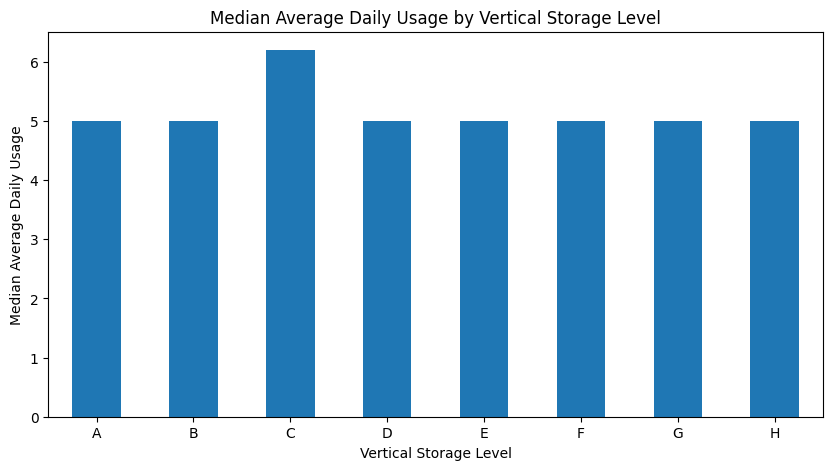

In [39]:
plt.figure(figsize=(10, 5))

usage_by_level.plot(kind='bar')

plt.title('Median Average Daily Usage by Vertical Storage Level')
plt.xlabel('Vertical Storage Level')
plt.ylabel('Median Average Daily Usage')
plt.xticks(rotation=0)

plt.show()

**Observation**: Median Average Daily Usage is relatively consistent across vertical storage levels A–H, with most levels having a median ADU of 5. Level C shows a slightly higher median usage. Overall, the results do not show a strong relationship between typical part usage and vertical storage level. However, because a large proportion of parts have an ADU of 5, median values alone may mask differences among higher-velocity parts.

In [40]:
# Find the ADU threshold for the top 20% of parts
high_usage_threshold = df['Average Daily Usage'].quantile(0.80)

high_usage_threshold

np.float64(31.4)

In [41]:
# Classify parts based on the top 20% ADU threshold
df['High_Usage'] = np.where(
    df['Average Daily Usage'] >= high_usage_threshold,
    1,
    0
)

df['High_Usage'].value_counts()

,count
High_Usage,
0,3985
1,1009


In [42]:
# Count high-usage parts by vertical storage level
high_usage_by_level = (
    df[df['Vertical_Level_Clean'].notnull()]
    .groupby('Vertical_Level_Clean')['High_Usage']
    .agg(['sum', 'count'])
)

# Calculate percentage of parts that are high usage at each level
high_usage_by_level['High_Usage_Percent'] = (
    high_usage_by_level['sum'] /
    high_usage_by_level['count'] * 100
)

high_usage_by_level

,sum,count,High_Usage_Percent
Vertical_Level_Clean,,,
A,45,385,11.688312
B,47,381,12.335958
C,75,307,24.429967
D,43,298,14.429530
E,49,248,19.758065
F,49,278,17.625899
G,53,256,20.703125
H,62,241,25.726141


**Observation**: High-usage SKUs are not concentrated exclusively at the lower vertical storage levels. Level H, the highest vertical level, has the largest proportion of high-usage parts at approximately 25.7%, while Levels A and B, the lowest levels, contain approximately 11.7% and 12.3%, respectively. This pattern suggests a potential slotting optimization opportunity, as some frequently used parts may be stored at less accessible vertical levels. However, additional operational constraints such as part size, weight, equipment requirements, and reserved storage locations would need to be considered before determining whether these SKUs are truly mis-slotted.

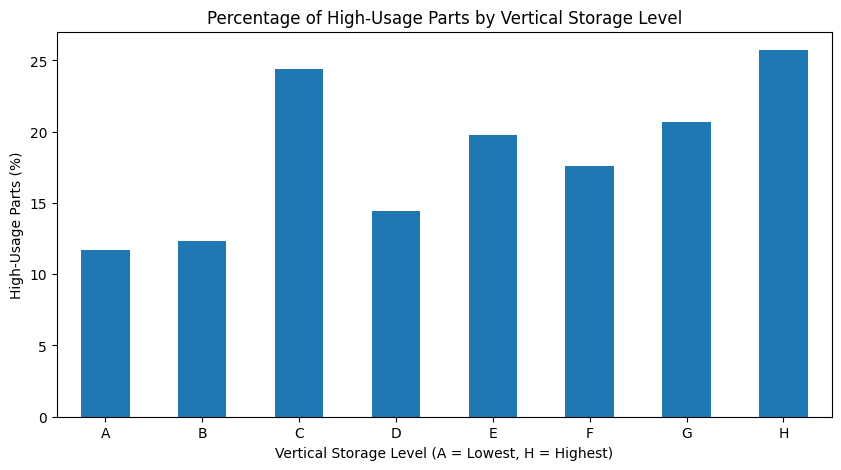

In [43]:
plt.figure(figsize=(10, 5))

high_usage_by_level['High_Usage_Percent'].plot(kind='bar')

plt.title('Percentage of High-Usage Parts by Vertical Storage Level')
plt.xlabel('Vertical Storage Level (A = Lowest, H = Highest)')
plt.ylabel('High-Usage Parts (%)')
plt.xticks(rotation=0)

plt.show()

In [44]:
# Count unique aisles
df['Aisle'].nunique()

13

In [45]:
# Count parts stored in each aisle
df['Aisle'].value_counts().sort_index()

,count
Aisle,
00,22
01,46
02,38
03,13
04,24
18,640
19,683
20,522
21,337


In [46]:
# Create subset for SM101 small-parts storage
sm101_df = df[df['Warehouse_Area'] == 'SM101'].copy()

# Check the number of parts and aisles represented
print("Number of SM101 parts:", len(sm101_df))
print("\nSM101 aisles:")
print(sm101_df['Aisle'].value_counts().sort_index())

Number of SM101 parts: 2182

SM101 aisles:
Aisle
18    640
19    683
20    522
21    337
Name: count, dtype: int64


In [47]:
# Calculate the top 20% usage threshold within SM101
sm101_high_usage_threshold = sm101_df['Average Daily Usage'].quantile(0.80)

sm101_high_usage_threshold

np.float64(26.2)

In [48]:
# Identify high-usage parts within SM101
sm101_df['High_Usage'] = np.where(
    sm101_df['Average Daily Usage'] >= sm101_high_usage_threshold,
    1,
    0
)

sm101_df['High_Usage'].value_counts()

,count
High_Usage,
0,1743
1,439


In [49]:
# Calculate high-usage concentration by SM101 aisle
high_usage_by_aisle = (
    sm101_df.groupby('Aisle')['High_Usage']
    .agg(['sum', 'count'])
)

high_usage_by_aisle['High_Usage_Percent'] = (
    high_usage_by_aisle['sum'] /
    high_usage_by_aisle['count'] * 100
)

high_usage_by_aisle

,sum,count,High_Usage_Percent
Aisle,,,
18,101,640,15.781250
19,104,683,15.226940
20,130,522,24.904215
21,104,337,30.860534


**Observation**: Within the SM101 small-parts storage area, high-usage SKUs are not evenly distributed across aisles. Aisle 21 has the highest concentration of high-usage parts at approximately 30.9%, followed by Aisle 20 at 24.9%. Aisles 18 and 19 have substantially lower concentrations at approximately 15–16%. This indicates that demand patterns vary by aisle and suggests that aisle location should be considered when evaluating current slotting practices.

In [50]:
# High-usage percentage by aisle and vertical level
aisle_level_analysis = (
    sm101_df
    .groupby(['Aisle', 'Vertical_Level_Clean'])['High_Usage']
    .agg(['sum', 'count'])
)

aisle_level_analysis['High_Usage_Percent'] = (
    aisle_level_analysis['sum'] /
    aisle_level_analysis['count'] * 100
)

aisle_level_analysis

sum  count  High_Usage_Percent
Aisle Vertical_Level_Clean                                
18    A                      15     70           21.428571
      B                      21     76           27.631579
      C                      22     98           22.448980
      D                       6     95            6.315789
      E                       8     68           11.764706
      F                      10     87           11.494253
      G                      10     68           14.705882
      H                       9     78           11.538462
19    A                       7     63           11.111111
      B                      15     86           17.441860
      C                      16     90           17.777778
      D                      11    101           10.891089
      E                       9     89           10.112360
      F                      20    100           20.000000
      G                      12     92           13.043478
      H                      14     62           22.580645
20    A                       9     61           14.754098
      B                       9     69           13.043478
      C                      23     59           38.983051
      D                      16     59           27.118644
      E                      21     67           31.343284
      F                      10     69           14.492754
      G                      17     67           25.373134
      H                      25     71           35.211268
21    A                       3    114            2.631579
      B                       2     88            2.272727
      C                      12     23           52.173913
      D                      13     21           61.904762
      E                      19     22           86.363636
      F                      18     22           81.818182
      G                      19     25           76.000000
      H                      18     22           81.818182

In [51]:
# Identify high-usage parts in Aisle 21 stored at upper levels E-H
aisle21_upper_high_usage = sm101_df[
    (sm101_df['Aisle'] == '21') &
    (sm101_df['Vertical_Level_Clean'].isin(['E', 'F', 'G', 'H'])) &
    (sm101_df['High_Usage'] == 1)
].copy()

# Sort by Average Daily Usage from highest to lowest
aisle21_upper_high_usage = aisle21_upper_high_usage.sort_values(
    'Average Daily Usage',
    ascending=False
)

# Display the top 20 parts
aisle21_upper_high_usage[
    [
        'Part number',
        'Part description',
        'Average Daily Usage',
        'Current Inventory levels (in pieces)',
        'Warehouse Storage Location',
        'Vertical_Level_Clean'
    ]
].head(20)

,Part number,Part description,Average Daily Usage,Current Inventory levels (in pieces),Warehouse Storage Location,Vertical_Level_Clean
3341,87669161,LOUVER GLOBAL,276.2,3684.0,SM101.21.H.04,H
803,47743826,CONNECTOR HYD 3/4 ORFS-ORB 3/4,183.4,650.0,SM101.21.E.17,E
1079,47947213,HOSE HYD CPLR CYL,183.4,1625.0,SM101.21.F.06,F
4092,91866780,HANDLE ADJUSTABLE LEVER,174.6,2943.0,SM101.21.F.09,F
3318,87627854,"LAMP, REAR STOP-TAIL",107.0,2379.0,SM101.21.F.01,F
3496,90355858,LAMP WORK 50W,103.0,2090.0,SM101.21.H.02,H
2713,84552202,SHEET SPEAKER BRACKET,92.0,8012.0,SM101.21.F.04,F
2577,84416163,FOAM UPPER CHASSIS LONG,92.0,6720.0,SM101.21.E.19,E
1906,51677586,HOSE HYD STEP TO CPLR 250 BAR,91.8,1080.0,SM101.21.F.05,F
2573,84412489,BOOT EH CONTROL,87.2,705.0,SM101.21.F.08,F


**Observation**: The SKU-level analysis confirms that several high-usage parts in Aisle 21 are currently stored at upper vertical levels E–H. For example, PN 87669161 has an Average Daily Usage of 276.2 and is stored at Level H, while several other parts with relatively high daily usage are stored across Levels E–H. Combined with the earlier finding that approximately 76–86% of parts at Levels E–H in Aisle 21 are classified as high usage, these results identify a group of potential candidates for slotting review. Relocating appropriate high-usage parts to more accessible lower levels could potentially improve material accessibility. However, physical and operational constraints such as part dimensions, weight, safety requirements, and reserved storage locations would need to be evaluated before recommending actual relocations.

In [52]:
# View GW warehouse areas and example locations
gw_df = df[
    df['Warehouse Storage Location'].str.startswith('GW', na=False)
].copy()

print("Number of GW parts:", len(gw_df))

print("\nGW Warehouse Areas:")
print(gw_df['Warehouse_Area'].value_counts())

print("\nExample GW Locations:")
print(gw_df['Warehouse Storage Location'].dropna().head(20))

Number of GW parts: 14

GW Warehouse Areas:
Warehouse_Area
GW110    8
GW111    4
GW320    2
Name: count, dtype: int64

Example GW Locations:
1182    GW110.00.H.64
1183    GW110.00.H.66
1517    GW111.00.G.02
1518    GW111.00.G.04
3774    GW110.00.H.61
3775    GW111.00.G.08
3776    GW111.00.G.06
3777    GW110.00.H.53
3778    GW110.00.H.67
3813    GW110.00.H.63
4166    GW110.00.H.62
4167    GW110.00.H.50
4208     GW320.CAB.01
4209     GW320.CAB.01
Name: Warehouse Storage Location, dtype: object


**Storage Location Data Limitation**: Detailed slotting analysis was primarily conducted on SM101 because it contained a sufficiently large number of PNs with recorded and consistently structured storage locations. Although 14 records were explicitly identified with GW storage locations, this should not be interpreted as representing the full GW inventory. A substantial number of PNs in the dataset have missing warehouse storage-location information, and some of these parts may belong to GW or other warehouse areas. Because their actual home locations could not be determined from the available WMS extract, they were not assigned to a storage area or included in location-specific slotting analysis.

## Additional visualization: SM101 aisle × vertical level

A heatmap communicates *where* high-usage parts are concentrated, rather than only showing aggregate vertical-level averages. Each cell represents the percentage of high-usage SKUs in that aisle/level; the companion count table is essential because percentages from small groups can be unstable. This is a prioritization aid, **not** a relocation instruction.

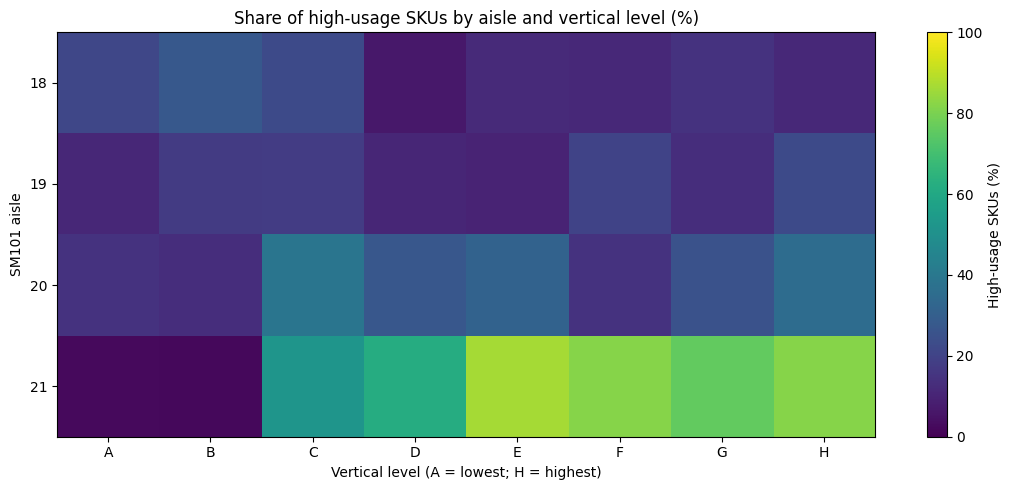

Vertical_Level_Clean,A,B,C,D,E,F,G,H
SM101 aisle,,,,,,,,
18,70,76,98,95,68,87,68,78
19,63,86,90,101,89,100,92,62
20,61,69,59,59,67,69,67,71
21,114,88,23,21,22,22,25,22


In [53]:
# Aggregated SM101 visualization; no SKU identifiers exposed
import matplotlib.pyplot as plt
heat = (sm101_df.dropna(subset=['Aisle', 'Vertical_Level_Clean'])
        .groupby(['Aisle', 'Vertical_Level_Clean'])['High_Usage']
        .agg(high_usage='sum', total='count'))
heat['pct'] = 100 * heat['high_usage'] / heat['total']
pct_grid = heat['pct'].unstack('Vertical_Level_Clean').reindex(columns=list('ABCDEFGH'))
count_grid = heat['total'].unstack('Vertical_Level_Clean').reindex(columns=list('ABCDEFGH'))
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pct_grid.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='viridis')
ax.set_xticks(range(len(pct_grid.columns)), pct_grid.columns)
ax.set_yticks(range(len(pct_grid.index)), pct_grid.index)
ax.set_xlabel('Vertical level (A = lowest; H = highest)')
ax.set_ylabel('SM101 aisle')
ax.set_title('Share of high-usage SKUs by aisle and vertical level (%)')
fig.colorbar(im, ax=ax, label='High-usage SKUs (%)')
plt.tight_layout()
plt.show()
display(count_grid.fillna(0).astype(int).rename_axis('SM101 aisle'))

In [54]:
# Exact within-aisle-and-level percentages, to accompany the count table
display(pct_grid.round(2).rename_axis('SM101 aisle'))


Vertical_Level_Clean,A,B,C,D,E,F,G,H
SM101 aisle,,,,,,,,
18,21.43,27.63,22.45,6.32,11.76,11.49,14.71,11.54
19,11.11,17.44,17.78,10.89,10.11,20.00,13.04,22.58
20,14.75,13.04,38.98,27.12,31.34,14.49,25.37,35.21
21,2.63,2.27,52.17,61.90,86.36,81.82,76.00,81.82


### Heatmap Interpretation and Operational Implications

The SM101 heatmap shows that the proportion of high-usage SKUs varies substantially across aisle and vertical level. **Aisle 21 stands out:** at the lowest levels, A and B, **2.63%** and **2.27%** of records respectively are classified as high usage, compared with **86.36% (E), 81.82% (F), 76.00% (G), and 81.82% (H)** at upper levels. The underlying count table shows **202 records at A–B** and **91 at E–H** in Aisle 21, so the percentage contrast should be interpreted alongside those unequal group sizes. The high-usage label is defined relative to the SM101-specific 80th-percentile ADU threshold (26.2), rather than a universal warehouse standard.

**Business implication:** Aisle 21 is a priority for investigating whether frequently used small parts could be placed at more accessible levels. These figures reveal a location-usage mismatch worth reviewing, **not proven mis-slotting**. Before any move, confirm SKU dimensions, weight, slot capacity, equipment access, safety requirements, and expected picking/travel benefits. A small controlled pilot with before-and-after picking-time measurements would test the potential value.


# **Baseline Model**
### **Modelling Question:** Can the warehouse characteristics currently available to us predict SKU usage?

In [55]:
model_df = sm101_df[
    [
        'Log_Average_Daily_Usage',
        'Log_Current_Inventory',
        'Aisle',
        'Vertical_Level_Clean'
    ]
].copy()

model_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2182 entries, 2 to 4993
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Log_Average_Daily_Usage  2182 non-null   float64
 1   Log_Current_Inventory    1781 non-null   float64
 2   Aisle                    2182 non-null   object 
 3   Vertical_Level_Clean     2182 non-null   object 
dtypes: float64(2), object(2)
memory usage: 85.2+ KB


In [56]:
X = model_df[
    ['Log_Current_Inventory', 'Aisle', 'Vertical_Level_Clean']
]

y = model_df['Log_Average_Daily_Usage']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2182, 3)
y shape: (2182,)


In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 1745
Testing records: 437


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

In [60]:
numeric_features = ['Log_Current_Inventory']

categorical_features = [
    'Aisle',
    'Vertical_Level_Clean'
]

In [61]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [62]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [63]:
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Log_Current_Inventory']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Aisle',
                                                   'Vertical_Level_Clean'])])),
                ('regressor', LinearRegression())])

In [64]:
y_pred = baseline_model.predict(X_test)

print("Number of predictions:", len(y_pred))
print("First 10 predictions:")
print(y_pred[:10])

Number of predictions: 437
First 10 predictions:
[2.26463685 3.35124077 2.42461348 1.29387134 3.01286248 2.4147041
 3.10425481 1.97622604 2.74684731 1.36955734]


In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R²:", round(r2, 3))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

R²: 0.276
MAE: 0.587
RMSE: 0.796


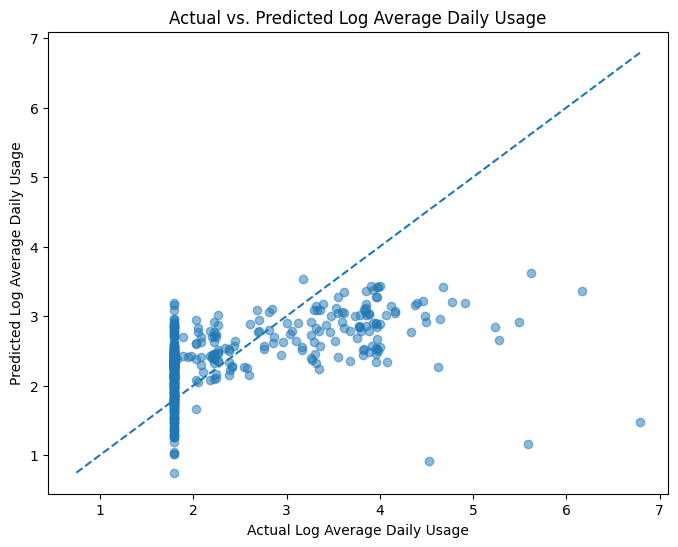

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.title('Actual vs. Predicted Log Average Daily Usage')
plt.xlabel('Actual Log Average Daily Usage')
plt.ylabel('Predicted Log Average Daily Usage')

plt.show()

**Observation**: The Actual vs. Predicted plot shows that the baseline model captures a general positive relationship between actual and predicted SKU usage, but prediction accuracy varies considerably. Predictions are concentrated within a narrower range than the actual values, and the model tends to underpredict SKUs with particularly high usage. The large concentration of observations near an actual log usage of approximately 1.79 reflects the large number of parts with an Average Daily Usage of 5. Overall, the visualization is consistent with the R² of 0.276 and indicates that inventory level and storage-location characteristics provide some predictive information but are insufficient to fully explain SKU usage.

**Baseline Model Evaluation:** The Linear Regression baseline model achieved an R² of 0.276, indicating that current inventory level, aisle, and vertical storage level explained approximately 27.6% of the variation in log-transformed Average Daily Usage on the test dataset. The model produced an MAE of 0.587 and an RMSE of 0.796. These results indicate that the available warehouse characteristics provide some predictive information about SKU usage, but a substantial portion of usage variation remains unexplained. This is reasonable for an initial baseline because important operational variables such as pick frequency, part dimensions, weight, handling requirements, production demand, and complete home-location information were unavailable. Future iterations of the slotting model could incorporate these variables to improve predictive performance and support more comprehensive slotting recommendations.

## Baseline rationale and benchmark comparison

**Why Linear Regression?** It is interpretable and establishes a simple starting point for predicting **log(1 + ADU)** using log inventory, aisle and vertical level. A train/test split holds out 20% of observations; imputation and encoding are fitted through the training pipeline. This model predicts demand rather than recommending slot moves, so it is an *intermediate analytical benchmark*.

**Metric interpretation:** R² measures the proportion of test-set variance explained relative to a mean prediction. MAE and RMSE are measured in **log(1 + ADU) units**, not original pieces/day. RMSE penalizes larger errors more heavily. Reported original results: **R² 0.276; MAE 0.587; RMSE 0.796**. Do not compare these directly with raw-ADU units.

The following additional check compares against a training-set mean predictor; it does **not** change the original fitted model or its reported metrics.

In [67]:
# Additional benchmark (preserves the original model and predictions)
from sklearn.dummy import DummyRegressor
mean_baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
mean_pred = mean_baseline.predict(X_test)
benchmark_comparison = pd.DataFrame({
    'Model': ['Training-mean baseline', 'Original linear regression'],
    'R2': [r2_score(y_test, mean_pred), r2_score(y_test, y_pred)],
    'MAE_log1p_ADU': [mean_absolute_error(y_test, mean_pred), mean_absolute_error(y_test, y_pred)],
    'RMSE_log1p_ADU': [np.sqrt(mean_squared_error(y_test, mean_pred)),
                       np.sqrt(mean_squared_error(y_test, y_pred))]
})
display(benchmark_comparison.round(3))

,Model,R2,MAE_log1p_ADU,RMSE_log1p_ADU
0,Training-mean baseline,-0.000,0.748,0.936
1,Original linear regression,0.276,0.587,0.796


**Limitations and next steps:** The original R² of 0.276 indicates limited explanatory power; predictions understate some high-usage SKUs. Compare the model to the mean benchmark, then consider nonlinear models only after obtaining pick frequency, travel distances, part dimensions, equipment requirements and handling constraints. Evaluate recommendations against operational constraints and measured picking effort before deployment.

# Findings and Conclusions

**Business problem.** Warehouse slotting should reduce unnecessary handling and travel while respecting physical, equipment, and safety constraints. This analysis identifies promising locations for further review; it does not directly optimize or prescribe storage assignments.

**Data and exploratory findings.** Average Daily Usage (ADU) and Current Inventory were highly right-skewed, so log transformations were used to moderate extreme values. Log-transformed usage and inventory had a moderate positive correlation of approximately **0.49**. Location-specific analysis focused on SM101 small-parts storage because it had sufficiently structured location data. The high-usage share in **Aisle 21** was **2.63% at A** and **2.27% at B**, compared with **86.36% at E, 81.82% at F, 76.00% at G, and 81.82% at H**. The relevant record counts were 202 at A–B and 91 at E–H. This uneven distribution is a practical screening signal, not proof that existing placements violate slotting constraints.

**Predictive findings.** The original Linear Regression model achieved **test R² = 0.276, MAE = 0.587, RMSE = 0.796**. Ridge Regression performed similarly (**R² = 0.275, MAE = 0.588, RMSE = 0.797**). **Random Forest** had the lowest five-fold training cross-validation RMSE (**0.710**) and the strongest held-out test results (**R² = 0.412, MAE = 0.469, RMSE = 0.717**). The mean-prediction benchmark had test RMSE **0.936**. Errors are expressed on the **log(1 + ADU)** scale, not in parts per day. Random Forest reduced test RMSE by about **9.9%** relative to Linear Regression; nevertheless, approximately **58.8% of test-set variation** remains unexplained relative to the mean-prediction benchmark.

**Actionable next steps.** First, review high-usage SKUs at upper Aisle 21 levels for feasible lower-level slots, subject to size, weight, capacity, reserved-space, safety, and handling constraints. Second, obtain historical pick frequency, travel distance, production demand, and complete home-location data to improve demand estimates. Third, pilot a small number of approved moves and measure pick/travel time and safety outcomes before scaling. The current predictive model estimates usage; **it does not itself recommend optimal slots**. Its performance is exploratory and should be validated on new time periods before operational deployment.


# Final Model Comparison and Hyperparameter Tuning

**Research question:** Do nonlinear models predict log-transformed SKU demand more accurately than the interpretable Linear Regression baseline?

**Candidate models:** Original Linear Regression, regularized Ridge Regression, and Random Forest Regression. Ridge controls coefficient magnitude; Random Forest can capture nonlinear effects and interactions. All models use the **same original train/test split and preprocessing**, so the original baseline results remain unchanged.

**Evaluation:** Use 5-fold shuffled cross-validation **only on the training partition** to select hyperparameters, with negative RMSE as the selection score. The final untouched test set is evaluated once per selected model using R², MAE and RMSE. MAE/RMSE are in log(1 + ADU) units. GridSearchCV may take a few minutes.

**Caution:** SKU records may be correlated by part family or location; random splitting does not establish performance on unseen time periods or new facilities. This is an exploratory predictive comparison, not proof that moving parts will improve picking efficiency.

In [68]:
# Multiple models + five-fold cross-validation + grid search (training data only)
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_specs = {
    'Linear Regression': (LinearRegression(), {}),
    'Ridge Regression': (Ridge(), {'regressor__alpha': [0.1, 1.0, 10.0, 100.0]}),
    'Random Forest': (RandomForestRegressor(random_state=42, n_jobs=1), {
        'regressor__n_estimators': [100, 200],
        'regressor__max_depth': [5, 10, None],
        'regressor__min_samples_leaf': [1, 5]
    })
}
model_rows = []
fitted_models = {}
for name, (estimator, param_grid) in model_specs.items():
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('regressor', estimator)
    ])
    search = GridSearchCV(pipeline, param_grid, cv=cv,
                          scoring='neg_root_mean_squared_error',
                          n_jobs=-1, refit=True, error_score='raise')
    search.fit(X_train, y_train)
    predictions = search.predict(X_test)
    fitted_models[name] = search.best_estimator_
    model_rows.append({
        'Model': name,
        'CV_RMSE_log1p_ADU': -search.best_score_,
        'Test_R2': r2_score(y_test, predictions),
        'Test_MAE_log1p_ADU': mean_absolute_error(y_test, predictions),
        'Test_RMSE_log1p_ADU': np.sqrt(mean_squared_error(y_test, predictions)),
        'Best_parameters': str(search.best_params_)
    })
final_model_comparison = pd.DataFrame(model_rows).sort_values('CV_RMSE_log1p_ADU')
display(final_model_comparison.round(3))


,Model,CV_RMSE_log1p_ADU,Test_R2,Test_MAE_log1p_ADU,Test_RMSE_log1p_ADU,Best_parameters
2,Random Forest,0.710,0.412,0.469,0.717,"{'regressor__max_depth': 5, 'regressor__min_sa..."
1,Ridge Regression,0.796,0.275,0.588,0.797,{'regressor__alpha': 10.0}
0,Linear Regression,0.796,0.276,0.587,0.796,{}


## Final Model Interpretation

**Model selection and evaluation.** Of the three tested approaches, **Random Forest Regression** had the lowest five-fold cross-validation RMSE on the training partition (**0.710**), compared with approximately **0.796** for both Linear Regression and Ridge Regression. GridSearchCV selected the Random Forest configuration using training data only; the held-out test set was used to assess the fitted model. The Random Forest test RMSE (**0.717**) is close to its cross-validation RMSE (**0.710**), providing some reassurance that the observed improvement is not confined to the cross-validation folds. This does not establish performance on future periods or unseen warehouses.

| Model | Test R² | Test MAE | Test RMSE |
|---|---:|---:|---:|
| Training-mean benchmark | −0.000 | 0.748 | 0.936 |
| Linear Regression | 0.276 | 0.587 | 0.796 |
| Ridge Regression | 0.275 | 0.588 | 0.797 |
| **Random Forest** | **0.412** | **0.469** | **0.717** |

**What the results mean.** Random Forest explains approximately **41.2%** of variation in held-out log-transformed ADU relative to a constant-mean prediction. Its test RMSE is approximately **9.9% lower** than the original Linear Regression model's (0.717 versus 0.796), and its MAE is also lower (0.469 versus 0.587). Ridge offers no meaningful improvement over the original linear model on these results. All MAE and RMSE values are on the **log(1 + ADU)** scale; they are not errors in physical pieces or daily picks.

**Business implications and limitations.** Nonlinear relationships between inventory and storage characteristics appear useful for predicting usage, but **predicting ADU is not the same as recommending an optimal slot**. With test R² of 0.412, substantial demand variation remains unexplained. Operational recommendations require actual pick frequency, slot dimensions and capacity, accessibility, weight, equipment/safety restrictions, travel time, and relocation costs. The next step is to validate demand estimates over time and test proposed relocations through a controlled operational pilot.


In [69]:
# Reproducible, nontechnical summary of the computed final model results
best_row = final_model_comparison.iloc[0]
print(f"Training-CV selected model: {best_row['Model']}")
print(f"5-fold CV RMSE (log1p ADU): {best_row['CV_RMSE_log1p_ADU']:.3f}")
print(f"Held-out test R²: {best_row['Test_R2']:.3f}")
print(f"Held-out test MAE (log1p ADU): {best_row['Test_MAE_log1p_ADU']:.3f}")
print(f"Held-out test RMSE (log1p ADU): {best_row['Test_RMSE_log1p_ADU']:.3f}")


Training-CV selected model: Random Forest
5-fold CV RMSE (log1p ADU): 0.710
Held-out test R²: 0.412
Held-out test MAE (log1p ADU): 0.469
Held-out test RMSE (log1p ADU): 0.717
